In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [61]:

df=pd.read_csv('/content/nepal_house_prices.csv')
df

,city,area_sqft,bedrooms,bathrooms,property_type,price_npr
0,ktm,1361,5,5,apartment,28766000
1,pokhara,1386,4,5,house,19689000
2,lalitpur,1686,3,2,townhouse,26671000
3,bkt,1983,5,4,house,24362000
4,ktm,2256,3,3,house,38683000
...,...,...,...,...,...,...
995,ktm,1517,5,4,house,32460000
996,pokhara,2310,4,4,townhouse,28411000
997,ktm,2844,6,5,apartment,58256000
998,pokhara,1007,2,3,apartment,12715000


In [62]:
df['city'].value_counts()

,count
city,
ktm,461
lalitpur,234
pokhara,153
bkt,152


In [63]:
df.isnull().sum()

,0
city,0
area_sqft,0
bedrooms,0
bathrooms,0
property_type,0
price_npr,0


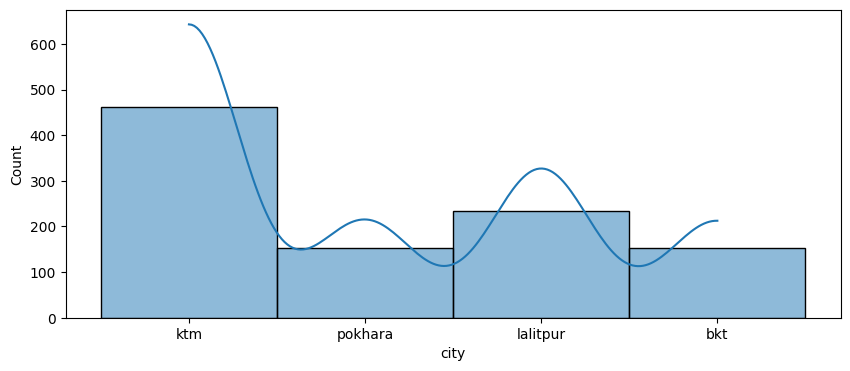

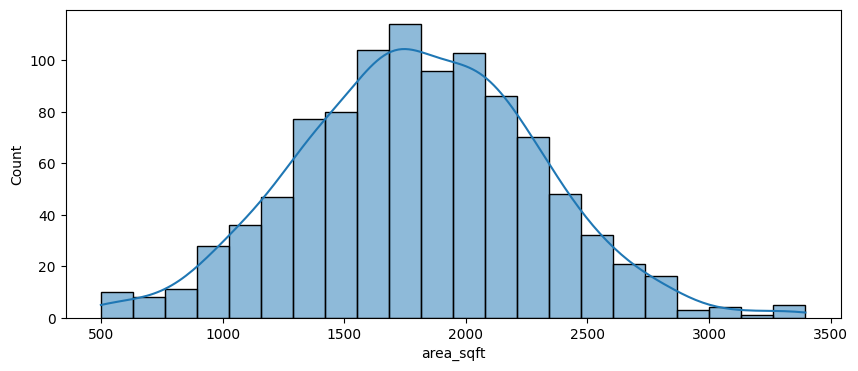

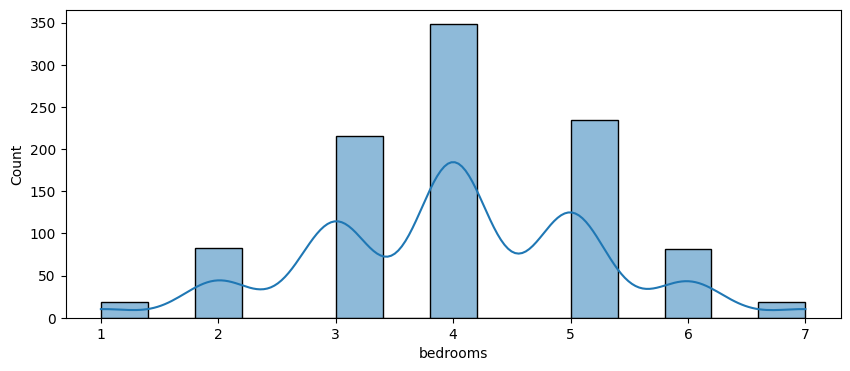

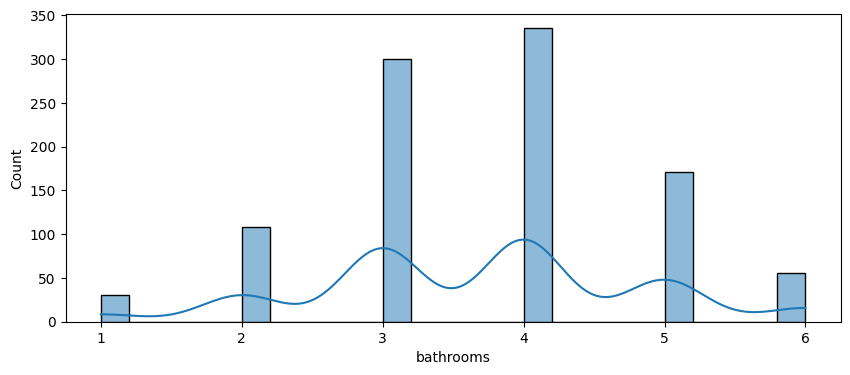

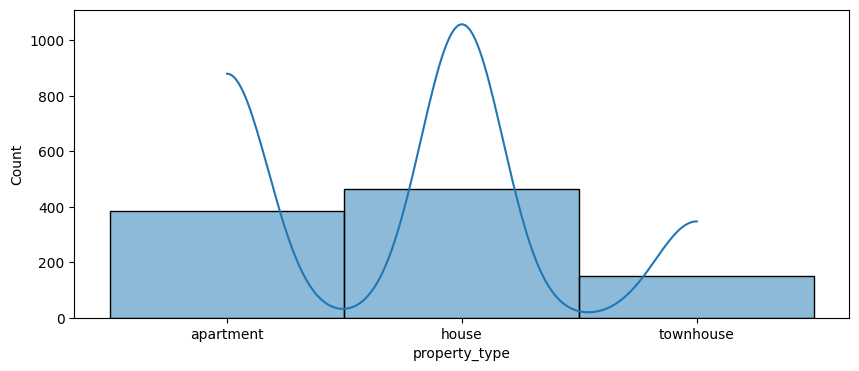

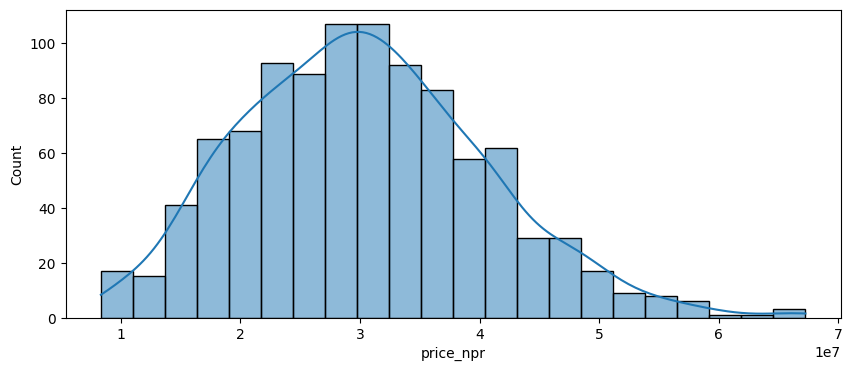

In [64]:
colum=df.columns
for col in colum:
  plt.figure(figsize=(10,4))
  sns.histplot(data=df,x=col,kde=True)



In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   city           1000 non-null   object
 1   area_sqft      1000 non-null   int64 
 2   bedrooms       1000 non-null   int64 
 3   bathrooms      1000 non-null   int64 
 4   property_type  1000 non-null   object
 5   price_npr      1000 non-null   int64 
dtypes: int64(4), object(2)
memory usage: 47.0+ KB


In [66]:
df['property_type'].value_counts()

,count
property_type,
house,463
apartment,385
townhouse,152


In [67]:
X=df.drop('price_npr',axis=1)
y=df['price_npr']

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [69]:
# Remove 'price_npr' from numerical features since it is the target y, not in X
numeric_cols = ['area_sqft', 'bedrooms', 'bathrooms']
norm_cols = ['city', 'property_type']

In [70]:
norm_pipeline = Pipeline(steps=[
    ('one_hot_encoding', OneHotEncoder(sparse_output=False)),  # Disable sparse matrix output
    ('standard_scaler', StandardScaler())
])

num_pipeline = Pipeline(steps=[
    ('standard_scaler', StandardScaler())
])

In [71]:
# Fix ColumnTransformer tuple format by adding names ('norm' and 'num')
col_trans = ColumnTransformer(transformers=[
    ('norm', norm_pipeline, norm_cols),
    ('num', num_pipeline, numeric_cols)
])

In [73]:
# Re-fit the preprocessor on training data and transform it now that sparse=False is set
X_train_transformed = col_trans.fit_transform(X_train)
X_train_transformed

array([[-0.42008403,  1.09168714, -0.55231974, ...,  1.19266823,
         0.82709949,  1.16552667],
       [-0.42008403, -0.91601335, -0.55231974, ..., -0.14414879,
         0.82709949,  1.16552667],
       [-0.42008403, -0.91601335,  1.81054546, ..., -1.36543843,
        -1.67294934, -0.59210073],
       ...,
       [-0.42008403, -0.91601335,  1.81054546, ..., -1.15088755,
         0.82709949,  0.28671297],
       [-0.42008403, -0.91601335,  1.81054546, ...,  0.54076363,
         0.82709949,  0.28671297],
       [-0.42008403,  1.09168714, -0.55231974, ...,  0.35715759,
        -0.00625012,  0.28671297]])

In [76]:
model=LinearRegression()
model.fit(X_train_transformed,y_train)

LinearRegression()

In [77]:
X_test_transformed = col_trans.fit_transform(X_test)
y_pred=model.predict(X_test_transformed)

In [79]:
r2=r2_score(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
print(f"Model R² Score: {r2:.4f}")
print(f"Model Mean Squared Error (MSE): {mse:.2f}")

Model R² Score: 0.8727
Model Mean Squared Error (MSE): 13705713058400.51


In [80]:
# 1. Define your custom house features here
custom_house = {
    'city': 'ktm',             # Choose from: 'ktm', 'lalitpur', 'pokhara', 'bkt'
    'area_sqft': 1500,         # Size of the house in sqft
    'bedrooms': 4,             # Number of bedrooms
    'bathrooms': 3,            # Number of bathrooms
    'property_type': 'house'   # Choose from: 'house', 'apartment', 'townhouse'
}

# 2. Convert the custom house to a DataFrame format
custom_df = pd.DataFrame([custom_house])

# 3. Transform the inputs using your fitted pipeline
custom_transformed = col_trans.transform(custom_df)

# 4. Predict the price using the trained model
predicted_price = model.predict(custom_transformed)[0]

print("--- Custom House Prediction ---")
for key, val in custom_house.items():
    print(f"{key.replace('_', ' ').title()}: {val}")
print("-------------------------------")
print(f"Predicted Price: Rs. {predicted_price:,.2f}")

--- Custom House Prediction ---
City: ktm
Area Sqft: 1500
Bedrooms: 4
Bathrooms: 3
Property Type: house
-------------------------------
Predicted Price: Rs. 29,626,373.48


In [83]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

In [85]:
classifier=GridSearchCV((model),
  param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)



In [86]:
classifier.fit(X_train_transformed,y_train)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


GridSearchCV(cv=5, estimator=LinearRegression(), n_jobs=-1,
             param_grid={'fit_intercept': [True, False],
                         'positive': [True, False]},
             scoring='r2', verbose=1)

In [87]:
y_pred_grid=classifier.predict(X_test_transformed)

In [89]:
r2_grid=r2_score(y_test,y_pred_grid)
mse_grid=mean_squared_error(y_test,y_pred_grid)
print(f"Model R² Score: {r2_grid:.4f}")
print(f"Model Mean Squared Error (MSE): {mse_grid:.2f}")

Model R² Score: 0.8761
Model Mean Squared Error (MSE): 13337993506038.03


In [90]:
from xgboost import XGBRegressor

In [91]:
model_sg=XGBRegressor()
model_sg.fit(X_train_transformed,y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [97]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0]
}

# Fix: Changed estimator from 'model' (LinearRegression) to 'model_sg' (XGBRegressor)
grid_search = GridSearchCV(
    estimator=model_sg,
    param_grid=param_grid,
    cv=2,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_transformed, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV R² Score:", grid_search.best_score_)

Fitting 2 folds for each of 54 candidates, totalling 108 fits
Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV R² Score: 0.8843274414539337


In [98]:
import pickle

# We will bundle both the preprocessor and the trained linear regression model into a dictionary
model_artifacts = {
    'preprocessor': col_trans,
    'model': model
}

# Save to a pickle file
file_path = 'nepal_house_price_lr_model.pkl'
with open(file_path, 'wb') as f:
    pickle.dump(model_artifacts, f)

print(f"Successfully saved the Linear Regression model and preprocessor to '{file_path}'!")

Successfully saved the Linear Regression model and preprocessor to 'nepal_house_price_lr_model.pkl'!


```markdown
### How to reload and use your saved pickle file later:

```python
import pickle
import pandas as pd

# 1. Load the artifacts back
with open('nepal_house_price_lr_model.pkl', 'rb') as f:
    loaded_artifacts = pickle.load(f)

loaded_preprocessor = loaded_artifacts['preprocessor']
loaded_model = loaded_artifacts['model']

# 2. Define custom input features
query_data = pd.DataFrame([{
    'city': 'ktm',
    'area_sqft': 1500,
    'bedrooms': 4,
    'bathrooms': 3,
    'property_type': 'house'
}])

# 3. Transform and predict
query_transformed = loaded_preprocessor.transform(query_data)
predicted_val = loaded_model.predict(query_transformed)[0]
print(f"Predicted Price: Rs. {predicted_val:,.2f}")
```
```